# Логистическая регрессия и методы оптимизации

**Цель работы:** сравнение обычного градиентного спуска, Nesterov Momentum и RMSprop на `affair_data.csv`. График точности строим **по обучающей выборке**; тестовые данные используем для итоговой проверки. Задание со звёздочкой не выполняется.

Запускайте ячейки сверху вниз. Файл `affair_data.csv` должен находиться рядом с ноутбуком.

## 1. Библиотеки и исходные данные

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_curve, roc_auc_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
data = pd.read_csv('affair_data.csv')
print('Размер данных:', data.shape)
print('Пропуски:', data.isna().sum().sum())
print('Распределение классов:')
print(data['affair'].value_counts())
display(data.head())

Размер данных: (6366, 9)
Пропуски: 0
Распределение классов:
affair
0    4313
1    2053
Name: count, dtype: int64


,rate_marriage,age,yrs_married,children,religious,educ,occupation,occupation_husb,affair
0,3.0,32.0,9.0,3.0,3.0,17.0,2.0,5.0,1
1,3.0,27.0,13.0,3.0,1.0,14.0,3.0,4.0,1
2,4.0,22.0,2.5,0.0,1.0,16.0,3.0,5.0,1
3,4.0,37.0,16.5,4.0,3.0,16.0,5.0,5.0,1
4,5.0,27.0,9.0,1.0,1.0,14.0,3.0,4.0,1


## 2. Подготовка данных

Как в учебном примере, выделяем 30% данных для теста. Масштабирование помогает градиентному спуску; `fit_transform` применяется только к обучающим данным, а `transform` — к тестовым. Столбец единиц нужен для свободного коэффициента модели.

In [2]:
X = data.drop(columns=['affair'])
y = data['affair'].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
y_train_np = y_train.to_numpy(dtype=float)
y_test_np = y_test.to_numpy(dtype=int)

# Добавляем столбец единиц для свободного коэффициента (bias).
X_train_bias = np.column_stack([np.ones(len(X_train_scaled)), X_train_scaled])
X_test_bias = np.column_stack([np.ones(len(X_test_scaled)), X_test_scaled])
print('Обучающая выборка:', X_train_bias.shape)
print('Тестовая выборка:', X_test_bias.shape)

Обучающая выборка: (4456, 9)
Тестовая выборка: (1910, 9)


## 3. Логистическая регрессия и функция потерь

Прогнозируем вероятность через сигмоиду: $p=1/(1+e^{-Xw})$. Минимизируем бинарную кросс-энтропию. Градиент равен $X^T(p-y)/N$. Это адаптация идеи градиентного спуска из лекции к логистической регрессии.

In [3]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1.0 / (1.0 + np.exp(-z))


def predict_proba(X, weights):
    return sigmoid(X @ weights)


def binary_cross_entropy(X, y, weights):
    p = np.clip(predict_proba(X, weights), 1e-12, 1 - 1e-12)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))


def gradient(X, y, weights):
    return (X.T @ (predict_proba(X, weights) - y)) / len(y)

## 4. Обучение тремя способами

**Эпоха** — один проход алгоритма обновления коэффициентов по всей обучающей выборке. **Скорость обучения** определяет величину шага.

- Обычный GD: делаем шаг против градиента.
- Nesterov: оцениваем градиент в точке «впереди» текущих коэффициентов.
- RMSprop: делим шаг на величину, зависящую от недавних квадратов градиента.

Число эпох и скорости обучения — выбранные для этого эксперимента настройки, **не заданные преподавателем**. Они различаются, поскольку методы имеют разные правила обновления. Их не подбираем по тестовой выборке.

In [4]:
EPOCHS = 160
LEARNING_RATES = {'Стандартный GD': 0.15, 'Nesterov Momentum': 0.08, 'RMSprop': 0.015}
BETA = 0.9
RHO = 0.9
EPSILON = 1e-8


def train_model(method, learning_rate, epochs=EPOCHS):
    weights = np.zeros(X_train_bias.shape[1], dtype=float)
    velocity = np.zeros_like(weights)
    squared_grad_avg = np.zeros_like(weights)
    history = {'epoch': [], 'train_accuracy': [], 'train_loss': []}

    for epoch in range(1, epochs + 1):
        if method == 'Стандартный GD':
            grad = gradient(X_train_bias, y_train_np, weights)
            weights -= learning_rate * grad
        elif method == 'Nesterov Momentum':
            lookahead = weights + BETA * velocity
            grad = gradient(X_train_bias, y_train_np, lookahead)
            velocity = BETA * velocity - learning_rate * grad
            weights += velocity
        elif method == 'RMSprop':
            grad = gradient(X_train_bias, y_train_np, weights)
            squared_grad_avg = RHO * squared_grad_avg + (1 - RHO) * grad**2
            weights -= learning_rate * grad / (np.sqrt(squared_grad_avg) + EPSILON)
        else:
            raise ValueError('Неизвестный метод оптимизации')

        train_pred = (predict_proba(X_train_bias, weights) >= 0.5).astype(int)
        history['epoch'].append(epoch)
        history['train_accuracy'].append(accuracy_score(y_train_np, train_pred))
        history['train_loss'].append(binary_cross_entropy(X_train_bias, y_train_np, weights))

    return weights, pd.DataFrame(history)

models = {}
histories = {}
for method, lr in LEARNING_RATES.items():
    models[method], histories[method] = train_model(method, lr)
    print(f'{method}: ошибка обучения = {histories[method]["train_loss"].iloc[-1]:.4f}')

Стандартный GD: ошибка обучения = 0.5451


Nesterov Momentum: ошибка обучения = 0.5422


RMSprop: ошибка обучения = 0.5422


## 5. Как меняется точность при обучении

На первом графике показана Accuracy **обучающей** выборки после каждой эпохи. Это позволяет наблюдать обучение, не обращаясь к тестовой выборке. На втором графике — функция потерь (чем меньше, тем лучше). Итоговое качество на тесте проверяем ниже.

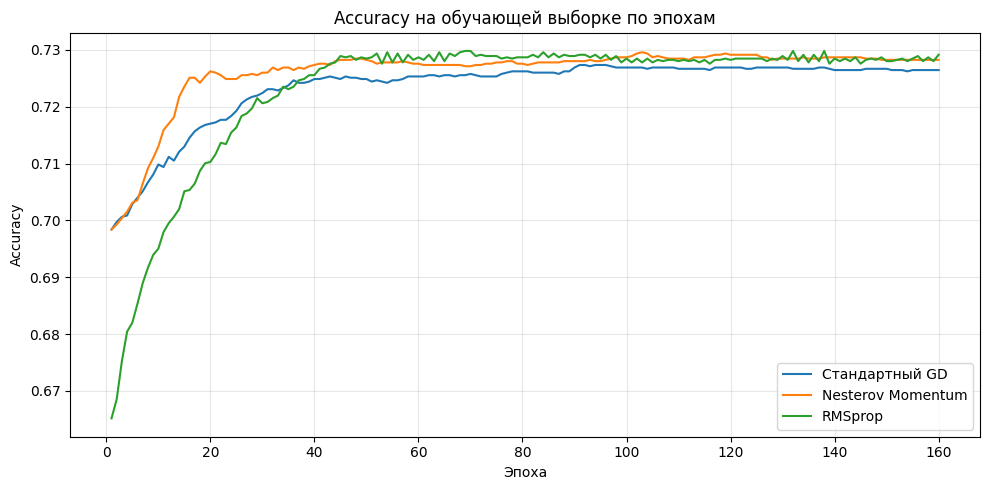

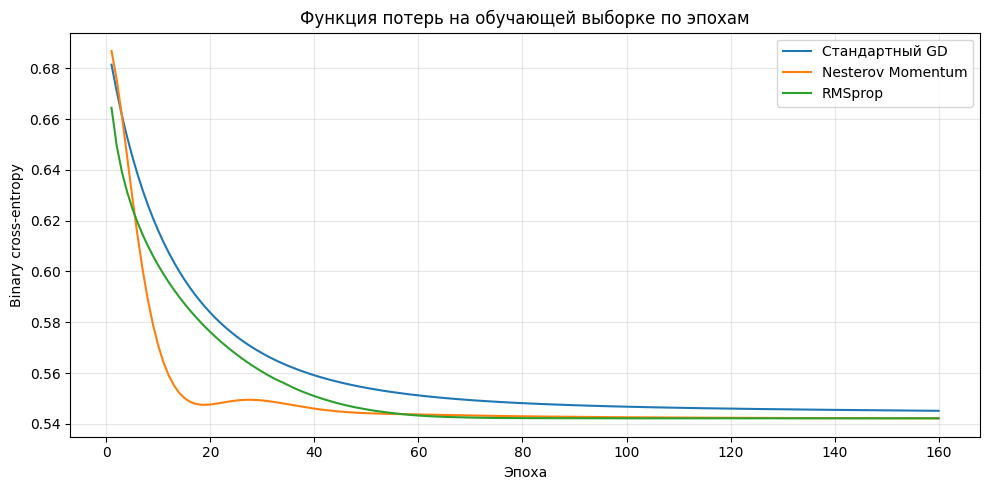

In [5]:
plt.figure(figsize=(10, 5))
for method, history in histories.items():
    plt.plot(history['epoch'], history['train_accuracy'], label=method)
plt.title('Accuracy на обучающей выборке по эпохам')
plt.xlabel('Эпоха')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
for method, history in histories.items():
    plt.plot(history['epoch'], history['train_loss'], label=method)
plt.title('Функция потерь на обучающей выборке по эпохам')
plt.xlabel('Эпоха')
plt.ylabel('Binary cross-entropy')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Проверка на тестовых данных: Accuracy, Precision, Recall

Теперь впервые используем отложенную тестовую выборку для итоговой оценки. **Accuracy** — доля верных ответов; **Precision** — доля верных среди предсказанных единиц; **Recall** — доля найденных единиц среди всех реальных единиц. Порог 0.5 означает: если вероятность не меньше 0.5, предсказываем класс 1. Другие пороги нужны для сравнения метрик.

In [6]:
THRESHOLDS = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
rows = []
for method, weights in models.items():
    probabilities = predict_proba(X_test_bias, weights)
    for threshold in THRESHOLDS:
        predictions = (probabilities >= threshold).astype(int)
        rows.append({
            'Метод': method,
            'Порог': threshold,
            'Accuracy': accuracy_score(y_test_np, predictions),
            'Precision': precision_score(y_test_np, predictions, zero_division=0),
            'Recall': recall_score(y_test_np, predictions, zero_division=0)
        })
metrics_table = pd.DataFrame(rows)
display(metrics_table.round(4))

,Метод,Порог,Accuracy,Precision,Recall
0,Стандартный GD,0.2,0.5471,0.4074,0.8896
1,Стандартный GD,0.3,0.6770,0.4994,0.7094
2,Стандартный GD,0.4,0.7110,0.5544,0.5292
3,Стандартный GD,0.5,0.7188,0.6048,0.3701
4,Стандартный GD,0.6,0.7136,0.6533,0.2386
5,Стандартный GD,0.7,0.6990,0.6723,0.1299
6,Стандартный GD,0.8,0.6822,0.6000,0.0438
7,Nesterov Momentum,0.2,0.5586,0.4126,0.8701
8,Nesterov Momentum,0.3,0.6827,0.5059,0.6997
9,Nesterov Momentum,0.4,0.7136,0.5588,0.5325


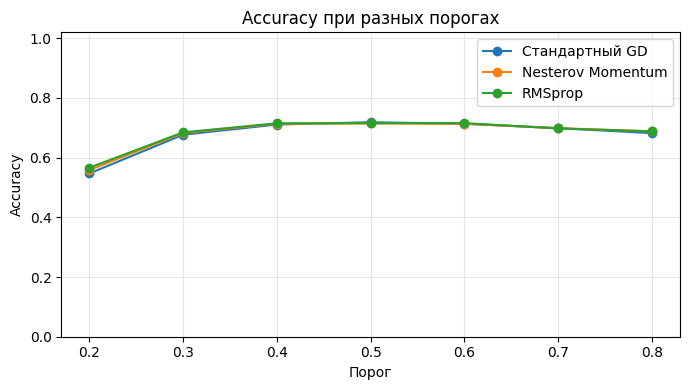

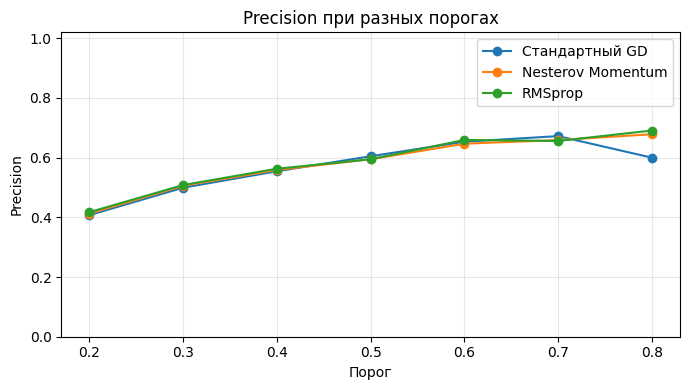

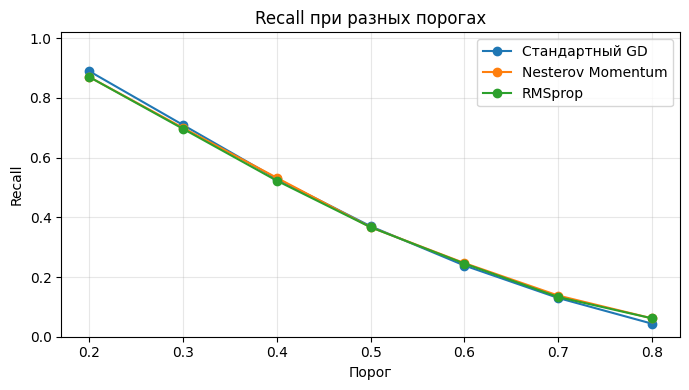

In [7]:
# По очереди строим отдельный график для каждой метрики.
for metric in ['Accuracy', 'Precision', 'Recall']:
    plt.figure(figsize=(7, 4))
    for method in LEARNING_RATES:
        group = metrics_table[metrics_table['Метод'] == method]
        plt.plot(group['Порог'], group[metric], marker='o', label=method)
    plt.title(f'{metric} при разных порогах')
    plt.xlabel('Порог')
    plt.ylabel(metric)
    plt.ylim(0, 1.02)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

## 7. ROC-кривая и ROC AUC

ROC показывает долю найденных положительных объектов (TPR) против доли ложных положительных срабатываний (FPR) при изменении порога. ROC AUC — площадь под кривой: чем ближе к 1, тем лучше ранжирование классов.

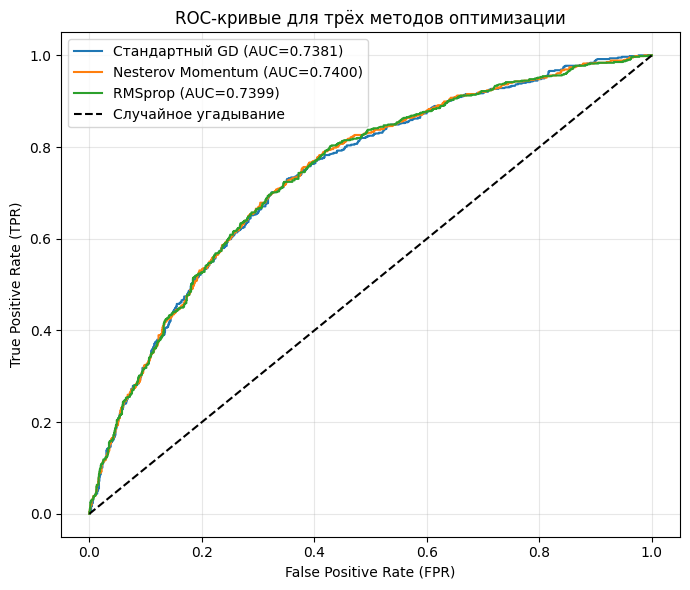

In [8]:
plt.figure(figsize=(7, 6))
auc_results = {}
for method, weights in models.items():
    probabilities = predict_proba(X_test_bias, weights)
    fpr, tpr, _ = roc_curve(y_test_np, probabilities)
    auc = roc_auc_score(y_test_np, probabilities)
    auc_results[method] = auc
    plt.plot(fpr, tpr, label=f'{method} (AUC={auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--', label='Случайное угадывание')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC-кривые для трёх методов оптимизации')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Итоговое сравнение

Для основной таблицы используем один стандартный порог **0.5**. Сначала считаем вероятности и предсказания, затем — метрики. Это делает код понятнее, чем длинные выражения в одной строке. **Важно:** методы сравниваются с заранее выбранными настройками, без подбора по тесту.

In [9]:
results = []
for method, weights in models.items():
    probabilities = predict_proba(X_test_bias, weights)
    predictions = (probabilities >= 0.5).astype(int)

    accuracy = accuracy_score(y_test_np, predictions)
    precision = precision_score(y_test_np, predictions, zero_division=0)
    recall = recall_score(y_test_np, predictions, zero_division=0)
    auc = auc_results[method]
    loss = histories[method]['train_loss'].iloc[-1]

    results.append({
        'Метод': method,
        'Accuracy (порог 0.5)': accuracy,
        'Precision (порог 0.5)': precision,
        'Recall (порог 0.5)': recall,
        'ROC AUC': auc,
        'Последний train loss': loss
    })

summary = pd.DataFrame(results)
display(summary.round(4))

best_accuracy_row = summary['Accuracy (порог 0.5)'].idxmax()
best_auc_row = summary['ROC AUC'].idxmax()
print('Лучший по Accuracy:', summary.loc[best_accuracy_row, 'Метод'])
print('Лучший по ROC AUC:', summary.loc[best_auc_row, 'Метод'])

,Метод,Accuracy (порог 0.5),Precision (порог 0.5),Recall (порог 0.5),ROC AUC,Последний train loss
0,Стандартный GD,0.7188,0.6048,0.3701,0.7381,0.5451
1,Nesterov Momentum,0.7152,0.5947,0.3669,0.7400,0.5422
2,RMSprop,0.7152,0.5947,0.3669,0.7399,0.5422


Лучший по Accuracy: Стандартный GD
Лучший по ROC AUC: Nesterov Momentum


### Выводы

1. Три алгоритма обучают **одну логистическую регрессию**, но по-разному обновляют коэффициенты.
2. График Accuracy по эпохам показывает изменения **на обучающих данных**, а итоговая таблица оценивает качество **на тестовых**.
3. При изменении порога меняются Accuracy, Precision и Recall. Высокая Accuracy сама по себе не гарантирует хорошего обнаружения класса 1.
4. ROC AUC сравнивает способность моделей различать классы при разных порогах.
5. Конкретные результаты и лучшие методы выводятся кодом в таблице выше. При других настройках результаты могут измениться.

**Ограничение:** это учебное сравнение фиксированных настроек. Для подбора скорости обучения и числа эпох нужна отдельная валидационная выборка. Тест не следует использовать для настройки модели.